In [4]:
from transformers import pipeline

classifier = pipeline(task="text-classification", model="SamLowe/roberta-base-go_emotions", top_k=None)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [5]:
sentences = ["I am not having a great day"]

model_outputs = classifier(sentences)
print(model_outputs[0])
# produces a list of dicts for each of the labels

[{'label': 'disappointment', 'score': 0.46669596433639526}, {'label': 'sadness', 'score': 0.3984943926334381}, {'label': 'annoyance', 'score': 0.06806610524654388}, {'label': 'neutral', 'score': 0.05703021585941315}, {'label': 'disapproval', 'score': 0.04423946887254715}, {'label': 'nervousness', 'score': 0.014850739389657974}, {'label': 'realization', 'score': 0.014059904962778091}, {'label': 'approval', 'score': 0.011267454363405704}, {'label': 'joy', 'score': 0.0063033816404640675}, {'label': 'remorse', 'score': 0.006221487186849117}, {'label': 'caring', 'score': 0.006029392126947641}, {'label': 'embarrassment', 'score': 0.005265498533844948}, {'label': 'anger', 'score': 0.004981442354619503}, {'label': 'disgust', 'score': 0.004259037785232067}, {'label': 'grief', 'score': 0.004002132453024387}, {'label': 'confusion', 'score': 0.003382926108315587}, {'label': 'relief', 'score': 0.0031404944602400064}, {'label': 'desire', 'score': 0.0028274687938392162}, {'label': 'admiration', 'scor

True
AUC Score for admiration: 0.9521604938271604
AUC Score for amusement: 0.9848242741182893
AUC Score for anger: 0.9431356981557784
AUC Score for annoyance: 0.8513051938515763
AUC Score for approval: 0.8559508013802735
AUC Score for caring: 0.9127683995408863
AUC Score for confusion: 0.944169324916163
AUC Score for curiosity: 0.954737466212793
AUC Score for desire: 0.9548170225813434
AUC Score for disappointment: 0.8838599380425669
AUC Score for disapproval: 0.9113847516186162
AUC Score for disgust: 0.9458684349286932
AUC Score for embarrassment: 0.9067993782279498
AUC Score for excitement: 0.9418551640127505
AUC Score for fear: 0.9663512470579212
AUC Score for gratitude: 0.9919620465741156
AUC Score for grief: 0.868781897558876
AUC Score for joy: 0.9567387647937197
AUC Score for love: 0.9890071272293848
AUC Score for nervousness: 0.9423615357384224
AUC Score for optimism: 0.9280569045142415
AUC Score for pride: 0.9055280909258917
AUC Score for realization: 0.824218882607163
AUC Scor

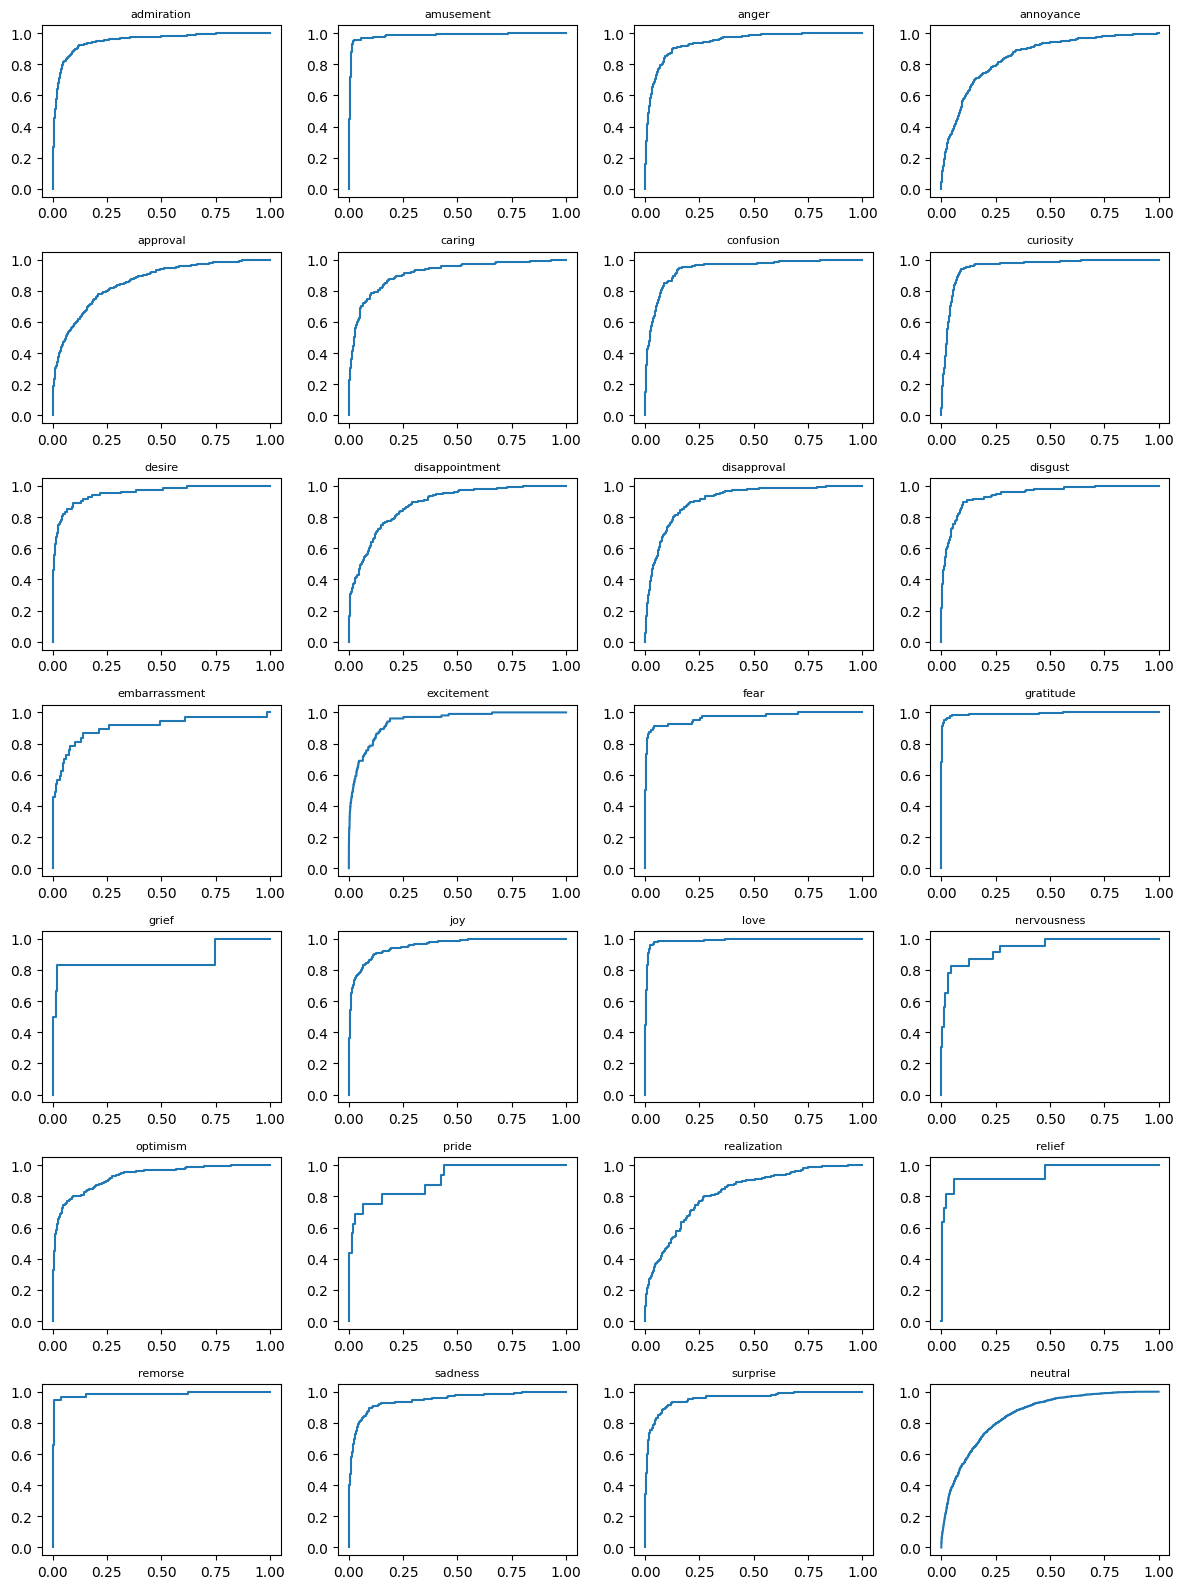

Threshold for admiration: 0.30000000000000004
Corresponding F1 Score: 0.7358309317963496
Threshold for amusement: 0.30000000000000004
Corresponding F1 Score: 0.8048411497730711
Threshold for anger: 0.30000000000000004
Corresponding F1 Score: 0.5118733509234829
Threshold for annoyance: 0.2
Corresponding F1 Score: 0.4190715181932246
Threshold for approval: 0.25
Corresponding F1 Score: 0.4072727272727273
Threshold for caring: 0.2
Corresponding F1 Score: 0.4742857142857143
Threshold for confusion: 0.30000000000000004
Corresponding F1 Score: 0.43967828418230565
Threshold for curiosity: 0.2
Corresponding F1 Score: 0.5608308605341247
Threshold for desire: 0.30000000000000004
Corresponding F1 Score: 0.5679012345679012
Threshold for disappointment: 0.15000000000000002
Corresponding F1 Score: 0.37176470588235294
Threshold for disapproval: 0.25
Corresponding F1 Score: 0.44810543657331137
Threshold for disgust: 0.15000000000000002
Corresponding F1 Score: 0.4549763033175355
Threshold for embarrassm

In [6]:
from datasets import load_dataset
import numpy as np
from sklearn.metrics import f1_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import torch # not done earlier in this model for some reason...

# setting up
ds = load_dataset("google-research-datasets/go_emotions", "simplified")
# take the model and tokenizer out of the pipeline
model, tokenizer = classifier.model, classifier.tokenizer
k = model.config.num_labels
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device).eval()
# emotion names in the dataset's order, used for printing
names = ds["train"].features["labels"].feature.names
model_names = [model.config.id2label[i] for i in range(k)]
print(model_names == names)

# turn dataset's labels into grid
def labels(d):
    y = np.zeros((d.num_rows, k))
    for i, labs in enumerate(d["labels"]):
        y[i, labs] = 1
    return y

# BERT
def probs(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        b = tokenizer(texts[i:i+bs], return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        with torch.no_grad():
            out.append(torch.sigmoid(model(**b).logits).cpu().numpy())
    return np.vstack(out)

# answer key
vy, ty = labels(ds["validation"]), labels(ds["test"])
# BERT's probabilities
vp, tp = probs(ds["validation"]["text"]), probs(ds["test"]["text"])
# reorder columns if the model's label order differs from the dataset's
if model_names != names:
    idx = [model_names.index(n) for n in names]
    vp, tp = vp[:, idx], tp[:, idx]

# roc curves and auc on test
fig, axs = plt.subplots(7, 4, figsize=(12, 16))
for i in range(k):
    fpr, tpr, _ = roc_curve(ty[:, i], tp[:, i])
    # 28 emotions fill a 7x4 grid, so row = i // 4 and column = i % 4
    axs[i // 4, i % 4].plot(fpr, tpr)
    axs[i // 4, i % 4].set_title(names[i], fontsize=8)
    print(f"AUC Score for {names[i]}: {roc_auc_score(ty[:, i], tp[:, i])}")
plt.tight_layout()
plt.show()

# cutoff per emotion (using validation)
grid = np.linspace(0.1, 0.9, 17)
th = []
for i in range(k):
    # f1 at each candidate cutoff for this emotion
    f1s = [f1_score(vy[:, i], vp[:, i] >= t) for t in grid]
    best = int(np.argmax(f1s))
    th.append(grid[best])
    print(f"Threshold for {names[i]}: {grid[best]}")
    print(f"Corresponding F1 Score: {f1s[best]}")

# f1 on test using the cutoffs from validation
f1 = []
for i in range(k):
    f1.append(f1_score(ty[:, i], tp[:, i] >= th[i]))
    print(f"F1 Scores on Test Data for {names[i]}: {f1[i]}")
# every emotion counts equally
print(f"\nMacro F1 Score: {np.mean(f1)}")